# Практическая работа № 1. Настройка окружения и первый notebook

**Дисциплина:** Машинное обучение · **Уровень:** B (данные заданы)
**Цель:** развернуть рабочее окружение и выполнить первичную загрузку и осмотр учебного датасета.

**Датасет:** `data/housing.csv` — учебные данные о продаже квартир (1010 строк). Целевая переменная — цена `price_kusd` (тыс. долларов). Данные синтетические, сгенерированы скриптом `src/make_data.py`, в них намеренно есть пропуски, выбросы и дубликаты.

## 1. Окружение

Использован **venv** (стандартный модуль Python): не требует установки дополнительных программ, а версии библиотек фиксируются в `requirements.txt` (обоснование также записано в README.md).

Команды настройки (Windows PowerShell):

```
python -m venv venv
.\venv\Scripts\Activate.ps1
pip install -r requirements.txt
jupyter notebook
```

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("matplotlib  :", matplotlib.__version__)

Python      : 3.12.3
pandas      : 3.0.2
numpy       : 2.4.4
matplotlib  : 3.10.8


## 2. Загрузка данных
Путь к файлу — **относительный** внутри репозитория (`../data/housing.csv`), чтобы ноутбук работал на любом компьютере.

In [2]:
df = pd.read_csv("../data/housing.csv")
df.head()

   area_m2  living_area_m2  area_sqft  rooms  floor  year_built  dist_center_km district        condition balcony  \
0     69.2            51.1      748.0      3   14.0      1995.0             7.6       Юг  требует ремонта      да   
1     34.1            25.2      370.0      2    5.0      1965.0             0.3    Центр            новый      да   
2     86.5            64.1      930.0      3   14.0      1974.0             8.6   Восток              NaN     нет   
3     33.5            23.5      361.0      2    4.0      1999.0             8.7    Север          хороший      да   
4     51.5            41.0      554.0      2   15.0      1982.0             8.7    Север          хороший      да   

   price_kusd  
0        89.9  
1        88.5  
2       102.2  
3        60.5  
4        68.5  

## 3. Первичный осмотр: размер, типы, пропуски, статистики

In [3]:
print("Размер таблицы (строк, столбцов):", df.shape)
print("\nТипы столбцов:")
print(df.dtypes)

Размер таблицы (строк, столбцов): (1010, 11)

Типы столбцов:
area_m2           float64
living_area_m2    float64
area_sqft         float64
rooms               int64
floor             float64
year_built        float64
dist_center_km    float64
district              str
condition             str
balcony               str
price_kusd        float64
dtype: object


In [4]:
print("Пропуски по столбцам (штук и в %):")
miss = pd.DataFrame({"пропусков": df.isnull().sum(),
                     "доля, %": (df.isnull().mean() * 100).round(1)})
miss

Пропуски по столбцам (штук и в %):


                пропусков  доля, %
area_m2                30      3.0
living_area_m2          0      0.0
area_sqft               0      0.0
rooms                   0      0.0
floor                  30      3.0
year_built             80      7.9
dist_center_km         50      5.0
district               60      5.9
condition             101     10.0
balcony                 0      0.0
price_kusd              0      0.0

In [5]:
df.describe().round(1).T

                 count    mean    std     min     25%     50%     75%     max
area_m2          980.0    69.1   63.9    20.5    48.0    61.2    77.5   990.0
living_area_m2  1010.0    46.4   16.9    12.7    35.0    43.7    55.0   127.4
area_sqft       1010.0   692.2  250.3   221.0   513.2   656.0   822.0  1884.0
rooms           1010.0     2.6    1.1     1.0     2.0     2.0     3.0     6.0
floor            980.0     8.5    4.6     1.0     4.0     9.0    12.0    16.0
year_built       930.0  1991.6   20.1  1800.0  1976.0  1991.0  2007.0  2099.0
dist_center_km   960.0     6.9    3.7     0.3     4.1     7.3     9.6    17.0
price_kusd      1010.0    95.0   32.3    10.0    72.0    91.2   113.9   226.3

## 4. Графики

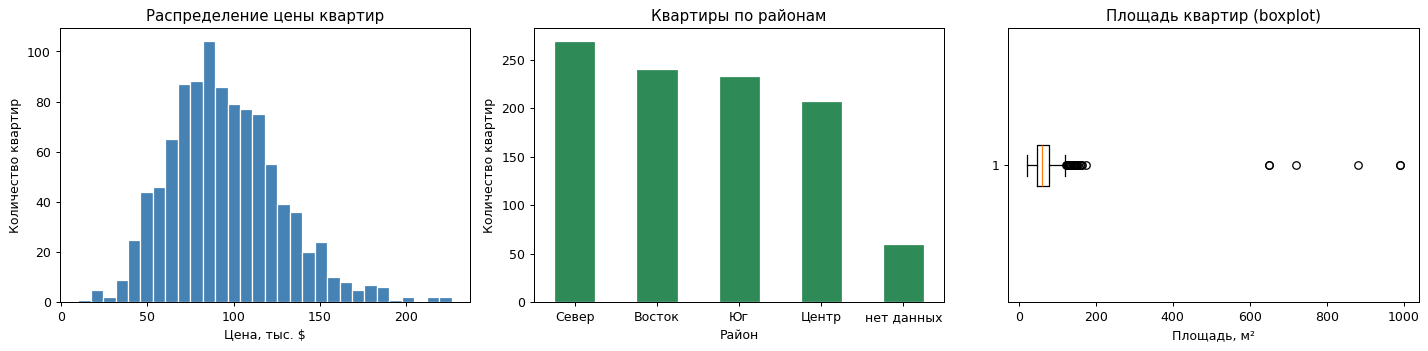

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df["price_kusd"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Распределение цены квартир")
axes[0].set_xlabel("Цена, тыс. $")
axes[0].set_ylabel("Количество квартир")

df["district"].value_counts(dropna=False).rename(index={np.nan: "нет данных"}).plot(
    kind="bar", ax=axes[1], color="seagreen", edgecolor="white")
axes[1].set_title("Квартиры по районам")
axes[1].set_xlabel("Район")
axes[1].set_ylabel("Количество квартир")
axes[1].tick_params(axis="x", rotation=0)

axes[2].boxplot(df["area_m2"].dropna(), vert=False)
axes[2].set_title("Площадь квартир (boxplot)")
axes[2].set_xlabel("Площадь, м²")

plt.tight_layout()
plt.show()

**Что видно на графиках.**
- *Цена:* распределение скошено вправо — основная масса квартир стоит 70–115 тыс. $, а небольшое число дорогих квартир тянет «хвост» вправо.
- *Районы:* квартиры распределены по районам относительно равномерно, самый большой район — Север; около 6% квартир вообще без указания района.
- *Площадь:* основная масса значений — до ~100 м², но на boxplot видны единичные точки далеко справа (сотни м²) — это явные аномалии.

In [7]:
# Факты, на которые опираются наблюдения ниже
print("Медиана и среднее цены:", df["price_kusd"].median(), "и", round(df["price_kusd"].mean(), 1))
print("Максимум площади, м²  :", df["area_m2"].max(), "| медиана:", df["area_m2"].median())
print("Год постройки min/max :", df["year_built"].min(), "/", df["year_built"].max())
print("Полных дубликатов строк:", df.duplicated().sum())
print("\nКорреляция с ценой:")
df.select_dtypes("number").corr()["price_kusd"].drop("price_kusd").round(2)

Медиана и среднее цены: 91.2 и 95.0
Максимум площади, м²  : 990.0 | медиана: 61.2
Год постройки min/max : 1800.0 / 2099.0
Полных дубликатов строк: 10

Корреляция с ценой:


area_m2           0.28
living_area_m2    0.78
area_sqft         0.79
rooms             0.68
floor             0.04
year_built       -0.01
dist_center_km   -0.33
Name: price_kusd, dtype: float64

## 5. Три содержательных наблюдения о данных

1. **В данных есть физически невозможные значения.** Максимальная площадь квартиры — 990 м² при медиане около 61 м², а год постройки лежит в диапазоне от 1800 до 2099 (2099 — это будущее). Это ошибки ввода, их нужно обработать до обучения модели.
2. **Выбросы «ломают» связь признака с ценой.** Корреляция цены с `area_m2` всего ≈ 0,28, тогда как с `living_area_m2` и `area_sqft` (по сути та же площадь) она ≈ 0,78. Разница возникла из-за нескольких опечаток в `area_m2` — один неверный признак маскирует реальную зависимость.
3. **Пропуски распределены неравномерно, а целевая переменная полная.** Больше всего пропусков в `condition` (≈ 10%) и `year_built` (≈ 8%), а в `price_kusd` их нет — значит, задачу регрессии можно ставить без потери строк. Кроме того, в таблице есть 10 полных дубликатов строк, которые нужно удалить, иначе одна и та же квартира попадёт и в обучающую, и в тестовую выборку.

**Вывод:** данные пригодны для обучения, но требуют очистки; этим мы займёмся в ПР-2 (анализ проблем) и ПР-3 (пайплайн предобработки).